# 自動車のピストンリング内径データ分析　坂井優希

`pistons.csv`（25サンプル × 各5個 = 125個の測定値、単位: mm）を使って、**ランキング・分布・管理図・工程能力**を調べる

**構成**
1. データの読み込み
2. 基本統計
3. サンプル別ランキング
4. 分布の確認（ヒストグラム・Q-Qプロット・正規性検定）
5. サンプル間のばらつき（箱ひげ図）
6. 管理図（X̄-R管理図）と異常判定
7. 測定順の推移・トレンド確認
8. 工程能力指数（Cp / Cpk）
9. まとめと考察

In [18]:
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/37.4 MB 6.3 MB/s eta 0:00:06
   -- ------------------------------------- 2.4/37.4 MB 6.5 MB/s eta 0:00:06
   --- ------------------------------------ 3.4/37.4 MB 5.9 MB/s eta 0:00:06
   ---- ----------------------------------- 4.5/37.4 MB 5.6 MB/s eta 0:00:06
   ------ --------------------------------- 5.8/37.4 MB 5.8 MB/s eta 0:00:06
   ------- -------------------------------- 6.8/37.4 MB 5.5 MB/s eta 0:00:06
   -------- ------------------------------- 7.9/37.4 MB 5.3 MB/s eta 0:00:06
   --------- ------------------------------ 8.7/37.4 MB 5.1 MB/s eta 0:00:06
   --------- ------------------------------ 9.2/37.4 MB 4.9 MB/s eta 0:00:06
   ---------- ----------------------------- 10.0/37.4 MB 4.7 MB/s eta 0:00:06
   ----------- ---------------------------- 10.7/37.4 MB 4.6 MB/s eta 0:00:06
   ------------ --------------------------- 11.8/37.4 MB 4.6 MB/s eta 0:00:06
   

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# CSVはShift_JIS(cp932)で保存されているので、文字コードを順に試す
for enc in ["cp932", "utf-8-sig", "utf-8"]:
    try:
        df = pd.read_csv("pistons.csv", encoding=enc)
        break
    except UnicodeDecodeError:
        continue

df.columns = ["sample", "size"]   # サンプル番号 / サイズ(mm)
df["order"] = np.arange(1, len(df) + 1)   # 測定順
print("文字コード:", enc, "/ 行数:", len(df))
display(df.head(10))

文字コード: cp932 / 行数: 125


,sample,size,order
0,1,74.030,1
1,1,74.002,2
2,1,74.019,3
3,1,73.992,4
4,1,74.008,5
5,2,73.995,6
6,2,73.992,7
7,2,74.001,8
8,2,74.011,9
9,2,74.004,10


## 2. 基本統計

In [20]:
display(df["size"].describe().round(4).to_frame("size (mm)"))
print("欠損値:", int(df.isna().sum().sum()))
print("サンプルあたりの個数:", df.groupby("sample").size().unique())
print("歪度: %.3f / 尖度: %.3f" % (stats.skew(df["size"]), stats.kurtosis(df["size"])))

,size (mm)
count,125.0000
mean,74.0012
std,0.0101
min,73.9670
25%,73.9940
50%,74.0010
75%,74.0080
max,74.0300


欠損値: 0
サンプルあたりの個数: [5]
歪度: -0.097 / 尖度: 0.381


## 3. サンプル別ランキング
サンプルごとに平均・標準偏差・範囲(最大−最小)を計算し、並べ替える
- **平均が高い／低い順**: 狙い値からのずれの目安
- **範囲が小さい順**: 小さいほどばらつきが少なく安定

In [21]:
g = df.groupby("sample")["size"].agg(["mean", "std", "min", "max"])
g["range"] = g["max"] - g["min"]
overall_mean = df["size"].mean()
g["dev_from_mean"] = g["mean"] - overall_mean
g = g.round(4)

print("■ 平均が高い順 TOP5")
display(g.sort_values("mean", ascending=False).head(5))
print("■ 平均が低い順 TOP5")
display(g.sort_values("mean").head(5))
print("■ ばらつきが小さい(範囲が小さい)順 TOP5 = 安定していたサンプル")
display(g.sort_values("range").head(5))
print("■ ばらつきが大きい(範囲が大きい)順 TOP5")
display(g.sort_values("range", ascending=False).head(5))

■ 平均が高い順 TOP5


,mean,std,min,max,range,dev_from_mean
sample,,,,,,
1,74.0102,0.0148,73.992,74.030,0.038,0.0090
20,74.0092,0.0080,74.000,74.020,0.020,0.0080
3,74.0080,0.0147,73.988,74.024,0.036,0.0068
18,74.0074,0.0070,74.000,74.018,0.018,0.0062
15,74.0060,0.0073,73.998,74.014,0.016,0.0048


■ 平均が低い順 TOP5


,mean,std,min,max,range,dev_from_mean
sample,,,,,,
14,73.9902,0.0153,73.967,74.006,0.039,-0.0110
11,73.9942,0.0029,73.990,73.998,0.008,-0.0070
6,73.9956,0.0087,73.985,74.009,0.024,-0.0056
16,73.9966,0.0078,73.984,74.005,0.021,-0.0046
8,73.9968,0.0123,73.985,74.015,0.030,-0.0044


■ ばらつきが小さい(範囲が小さい)順 TOP5 = 安定していたサンプル


,mean,std,min,max,range,dev_from_mean
sample,,,,,,
11,73.9942,0.0029,73.990,73.998,0.008,-0.0070
12,74.0014,0.0042,73.996,74.007,0.011,0.0002
7,74.0000,0.0055,73.994,74.006,0.012,-0.0012
9,74.0042,0.0055,73.995,74.009,0.014,0.0030
15,74.0060,0.0073,73.998,74.014,0.016,0.0048


■ ばらつきが大きい(範囲が大きい)順 TOP5


,mean,std,min,max,range,dev_from_mean
sample,,,,,,
14,73.9902,0.0153,73.967,74.006,0.039,-0.0110
1,74.0102,0.0148,73.992,74.030,0.038,0.0090
3,74.0080,0.0147,73.988,74.024,0.036,0.0068
25,73.9982,0.0162,73.982,74.017,0.035,-0.0030
8,73.9968,0.0123,73.985,74.015,0.030,-0.0044


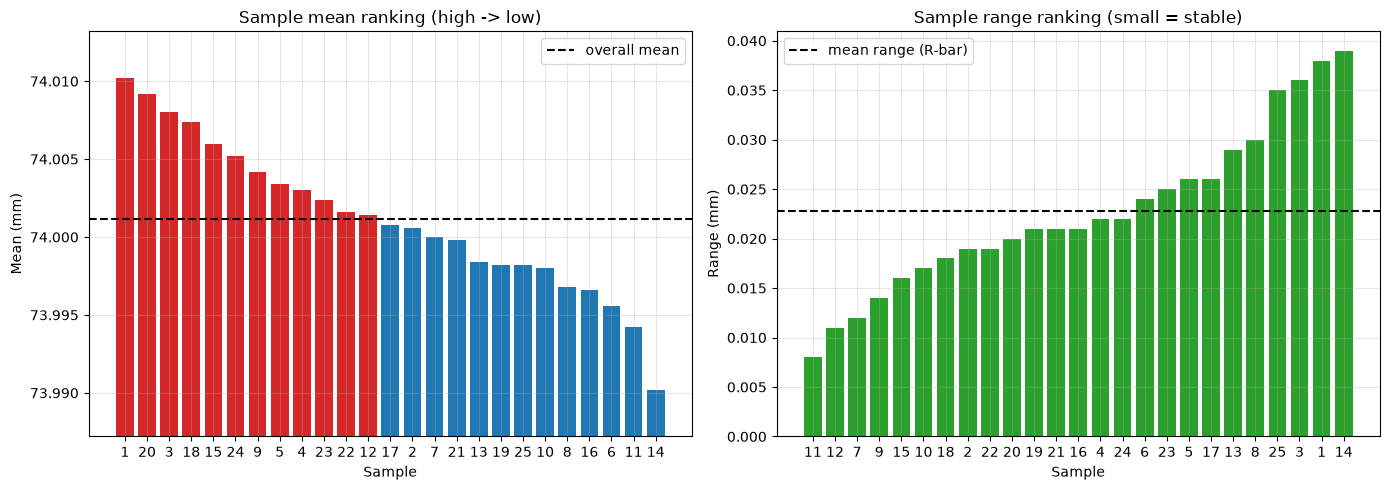

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

s = g.sort_values("mean", ascending=False)
colors = ["tab:red" if v > 0 else "tab:blue" for v in s["dev_from_mean"]]
axes[0].bar(s.index.astype(str), s["mean"], color=colors)
axes[0].axhline(overall_mean, color="k", ls="--", label="overall mean")
axes[0].set_ylim(s["mean"].min() - 0.003, s["mean"].max() + 0.003)
axes[0].set_title("Sample mean ranking (high -> low)")
axes[0].set_xlabel("Sample"); axes[0].set_ylabel("Mean (mm)")
axes[0].legend()

r = g.sort_values("range")
axes[1].bar(r.index.astype(str), r["range"], color="tab:green")
axes[1].axhline(g["range"].mean(), color="k", ls="--", label="mean range (R-bar)")
axes[1].set_title("Sample range ranking (small = stable)")
axes[1].set_xlabel("Sample"); axes[1].set_ylabel("Range (mm)")
axes[1].legend()
plt.tight_layout(); plt.show()

## 4. 分布の確認
個々の測定値が正規分布に従うかを、ヒストグラム・Q-Qプロット・Shapiro-Wilk検定で確認する

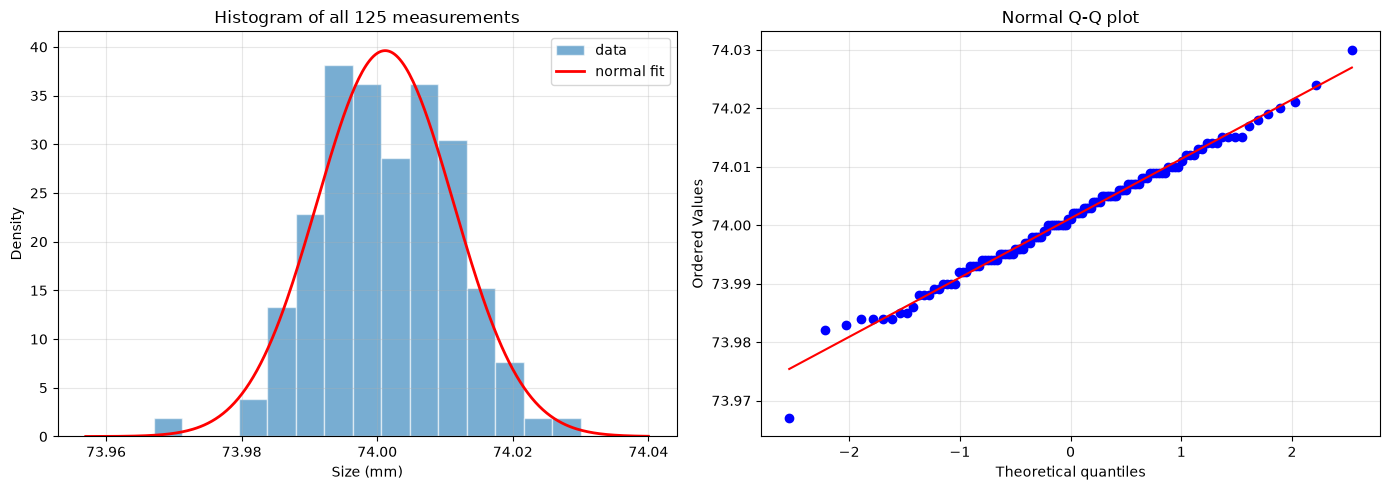

Shapiro-Wilk: W=0.9929, p=0.7861 -> 正規性を棄却できない(正規分布とみなせる)


In [23]:
x = df["size"]
mu, sd = x.mean(), x.std()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(x, bins=15, density=True, alpha=0.6, edgecolor="white", label="data")
xs = np.linspace(x.min() - 0.01, x.max() + 0.01, 300)
axes[0].plot(xs, stats.norm.pdf(xs, mu, sd), "r-", lw=2, label="normal fit")
axes[0].set_title("Histogram of all 125 measurements")
axes[0].set_xlabel("Size (mm)"); axes[0].set_ylabel("Density"); axes[0].legend()

stats.probplot(x, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot")
plt.tight_layout(); plt.show()

w, p = stats.shapiro(x)
print("Shapiro-Wilk: W=%.4f, p=%.4f -> %s" % (w, p, "正規性を棄却できない(正規分布とみなせる)" if p > 0.05 else "正規分布から外れている"))

## 5. サンプル間のばらつき（箱ひげ図）

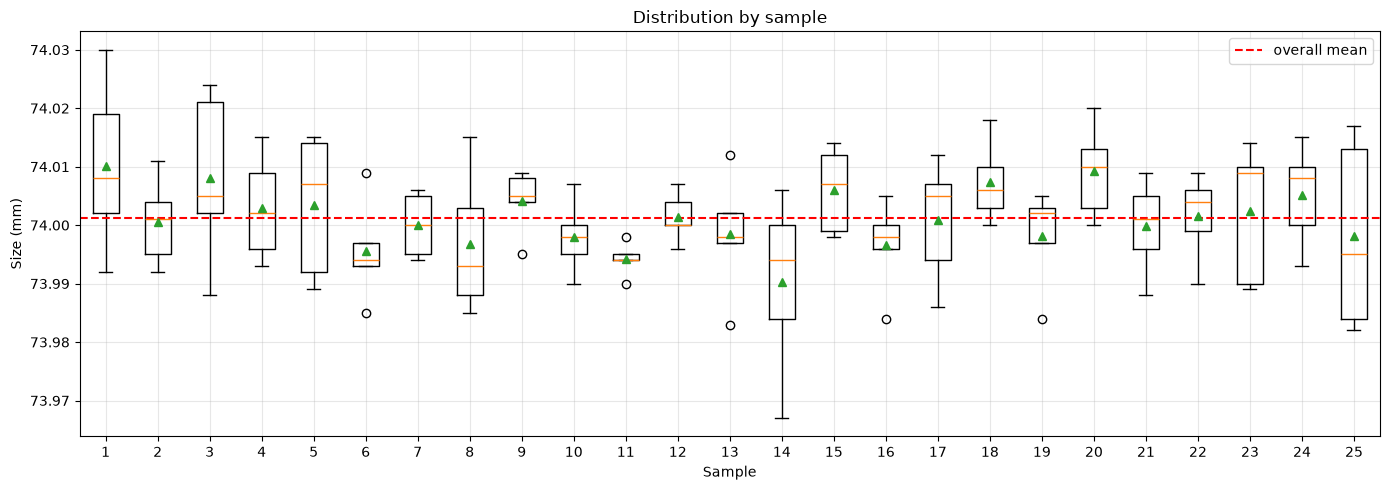

In [24]:
fig, ax = plt.subplots(figsize=(14, 5))
data = [df.loc[df["sample"] == i, "size"].values for i in sorted(df["sample"].unique())]
ax.boxplot(data, showmeans=True)
ax.set_xticks(range(1, len(data) + 1))
ax.set_xticklabels(sorted(df["sample"].unique()))
ax.axhline(overall_mean, color="r", ls="--", label="overall mean")
ax.set_title("Distribution by sample")
ax.set_xlabel("Sample"); ax.set_ylabel("Size (mm)"); ax.legend()
plt.tight_layout(); plt.show()

## 6. 管理図（X̄-R管理図）
工程が安定している(管理状態にある)かを確認します。n=5 の係数は A2=0.577, D3=0, D4=2.114, d2=2.326 です。

- X̄管理図: 中心線 = X̄̄、限界 = X̄̄ ± A2·R̄
- R管理図: 中心線 = R̄、上限 = D4·R̄、下限 = D3·R̄

X-bar chart: CL=74.0012, UCL=74.0143, LCL=73.9880
R chart    : CL=0.0228, UCL=0.0481, LCL=0.0000
X-bar 管理限界外のサンプル: なし
R     管理限界外のサンプル: なし


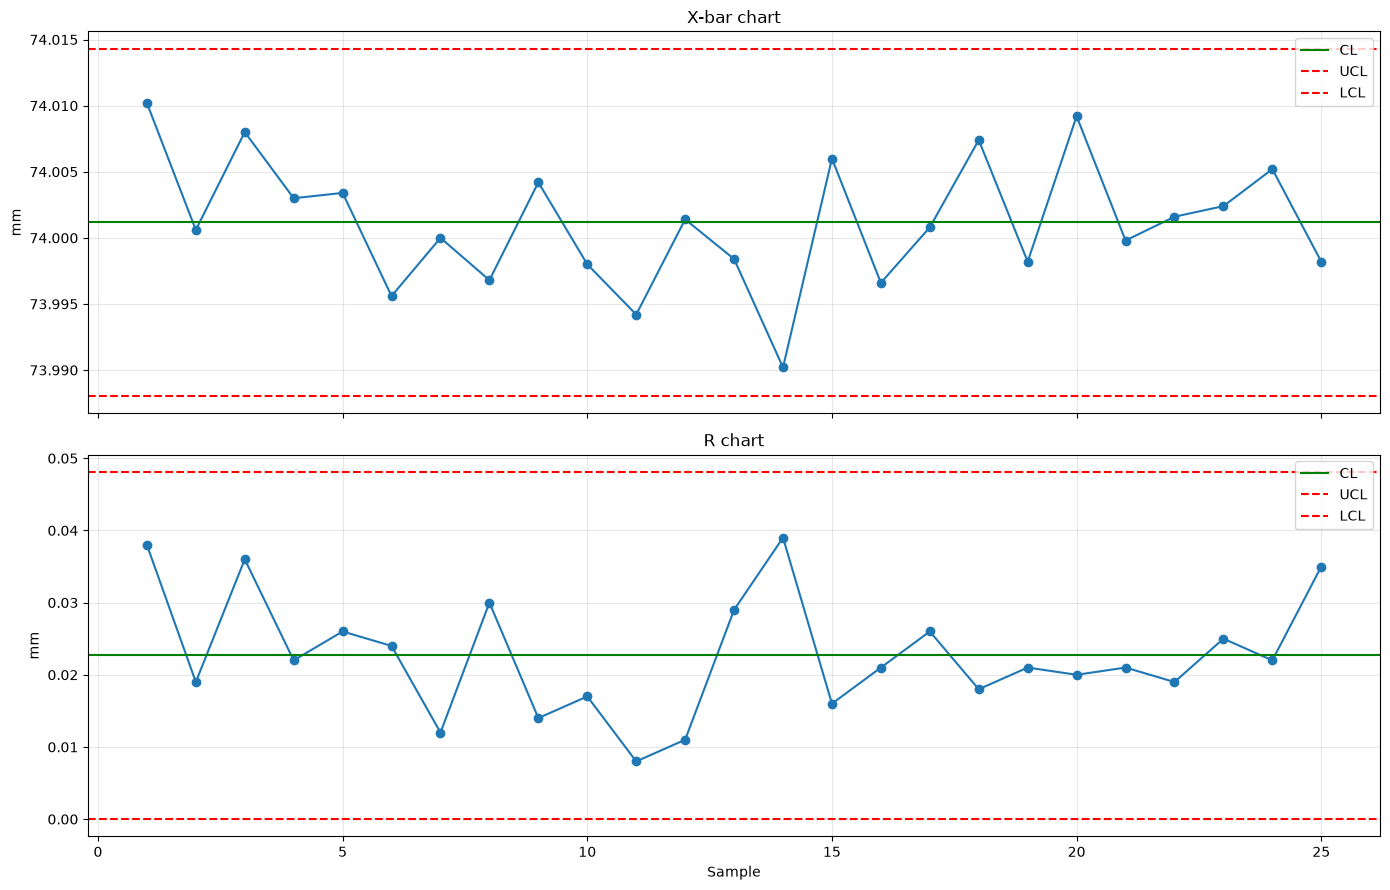

In [25]:
n = 5
A2, D3, D4, d2 = 0.577, 0.0, 2.114, 2.326

xbar = df.groupby("sample")["size"].mean()
rng = df.groupby("sample")["size"].agg(lambda v: v.max() - v.min())
xbb, rbar = xbar.mean(), rng.mean()

UCLx, LCLx = xbb + A2 * rbar, xbb - A2 * rbar
UCLr, LCLr = D4 * rbar, D3 * rbar

print("X-bar chart: CL=%.4f, UCL=%.4f, LCL=%.4f" % (xbb, UCLx, LCLx))
print("R chart    : CL=%.4f, UCL=%.4f, LCL=%.4f" % (rbar, UCLr, LCLr))

out_x = xbar[(xbar > UCLx) | (xbar < LCLx)]
out_r = rng[(rng > UCLr) | (rng < LCLr)]
print("X-bar 管理限界外のサンプル:", list(out_x.index) if len(out_x) else "なし")
print("R     管理限界外のサンプル:", list(out_r.index) if len(out_r) else "なし")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, y, cl, ucl, lcl, name in [
    (axes[0], xbar, xbb, UCLx, LCLx, "X-bar chart"),
    (axes[1], rng, rbar, UCLr, LCLr, "R chart"),
]:
    ax.plot(y.index, y.values, "o-", color="tab:blue")
    ax.axhline(cl, color="g", label="CL")
    ax.axhline(ucl, color="r", ls="--", label="UCL")
    ax.axhline(lcl, color="r", ls="--", label="LCL")
    bad = y[(y > ucl) | (y < lcl)]
    ax.scatter(bad.index, bad.values, color="red", s=120, zorder=5)
    ax.set_title(name); ax.set_ylabel("mm"); ax.legend(loc="upper right")
axes[1].set_xlabel("Sample")
plt.tight_layout(); plt.show()

In [26]:
# 追加の異常判定ルール(ウェスタン・エレクトリック系の簡易版)
def longest_run_one_side(v, center):
    side = np.sign(v - center)
    best = cur = 0
    prev = 0
    for s in side:
        if s != 0 and s == prev:
            cur += 1
        else:
            cur = 1 if s != 0 else 0
        prev = s
        best = max(best, cur)
    return best

def longest_monotone(v):
    best = cur_up = cur_dn = 1
    for a, b in zip(v[:-1], v[1:]):
        cur_up = cur_up + 1 if b > a else 1
        cur_dn = cur_dn + 1 if b < a else 1
        best = max(best, cur_up, cur_dn)
    return best

run = longest_run_one_side(xbar.values, xbb)
mono = longest_monotone(xbar.values)
sigma_xbar = (UCLx - xbb) / 3
n_2sigma = int(((xbar - xbb).abs() > 2 * sigma_xbar).sum())

print("中心線の同じ側に連続して並んだ最大の点数: %d (8点以上で異常の目安)" % run)
print("連続して増加/減少した最大の点数: %d (6点以上で異常の目安)" % mono)
print("2σを超えた点の数: %d / %d" % (n_2sigma, len(xbar)))

中心線の同じ側に連続して並んだ最大の点数: 3 (8点以上で異常の目安)
連続して増加/減少した最大の点数: 4 (6点以上で異常の目安)
2σを超えた点の数: 2 / 25


## 7. 測定順の推移・トレンド確認

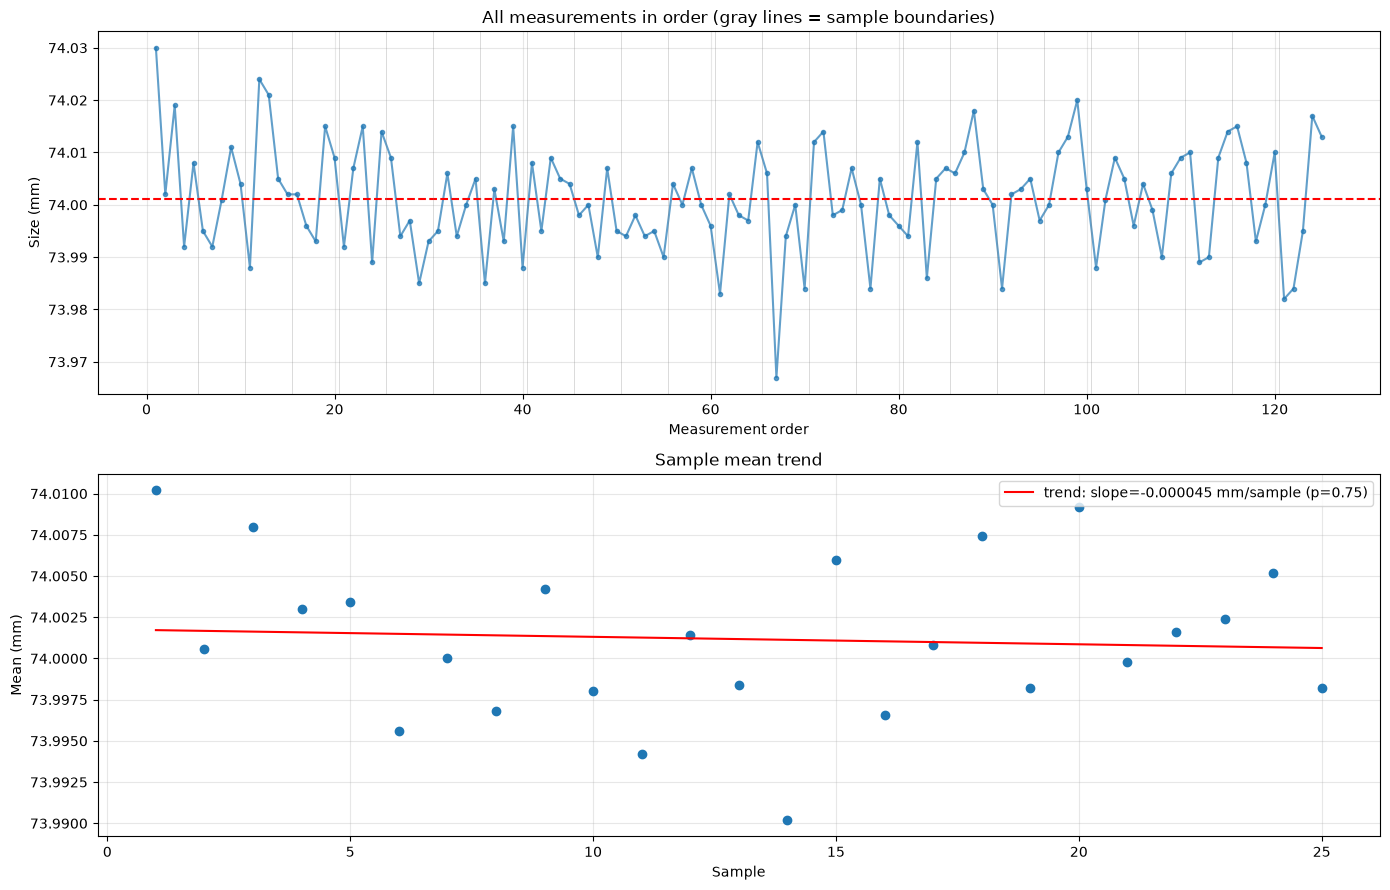

一元配置分散分析: F=1.219, p=0.245 -> サンプル間に有意な平均差なし
群内σ(R-bar/d2)=0.00979, 全体σ=0.01007, 平均値のσ=0.00487 (理論値 全体σ/√5=0.00450)


In [27]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(df["order"], df["size"], ".-", alpha=0.7)
axes[0].axhline(overall_mean, color="r", ls="--")
for b in np.arange(5.5, 125, 5):
    axes[0].axvline(b, color="gray", lw=0.5, alpha=0.4)
axes[0].set_title("All measurements in order (gray lines = sample boundaries)")
axes[0].set_xlabel("Measurement order"); axes[0].set_ylabel("Size (mm)")

lr = stats.linregress(xbar.index, xbar.values)
axes[1].plot(xbar.index, xbar.values, "o")
axes[1].plot(xbar.index, lr.intercept + lr.slope * xbar.index, "r-",
             label="trend: slope=%.6f mm/sample (p=%.2f)" % (lr.slope, lr.pvalue))
axes[1].set_title("Sample mean trend")
axes[1].set_xlabel("Sample"); axes[1].set_ylabel("Mean (mm)"); axes[1].legend()
plt.tight_layout(); plt.show()

# サンプル間の平均差があるか(一元配置分散分析)
f, p = stats.f_oneway(*[df.loc[df["sample"] == i, "size"].values for i in sorted(df["sample"].unique())])
print("一元配置分散分析: F=%.3f, p=%.3f -> %s" % (f, p, "サンプル間に有意な平均差なし" if p > 0.05 else "サンプル間に有意な差あり"))

# 群内ばらつきと群間ばらつき
sigma_within = rbar / d2
sigma_total = df["size"].std()
print("群内σ(R-bar/d2)=%.5f, 全体σ=%.5f, 平均値のσ=%.5f (理論値 全体σ/√5=%.5f)"
      % (sigma_within, sigma_total, xbar.std(), sigma_total / np.sqrt(n)))

## 8. 工程能力指数（Cp / Cpk）
規格(仕様)が与えられていないため、**仮に 74.000 ± 0.050 mm** として計算しています。実際の規格に合わせて下のセルの `target` と `tol` を書き換えてください。

,value
LSL,73.9500
USL,74.0500
mean,74.0012
sigma(within),0.0098
Cp,1.7033
Cpk,1.6632
Pp,1.6551
Ppk,1.6162
expected out-of-spec (ppm),0.3872


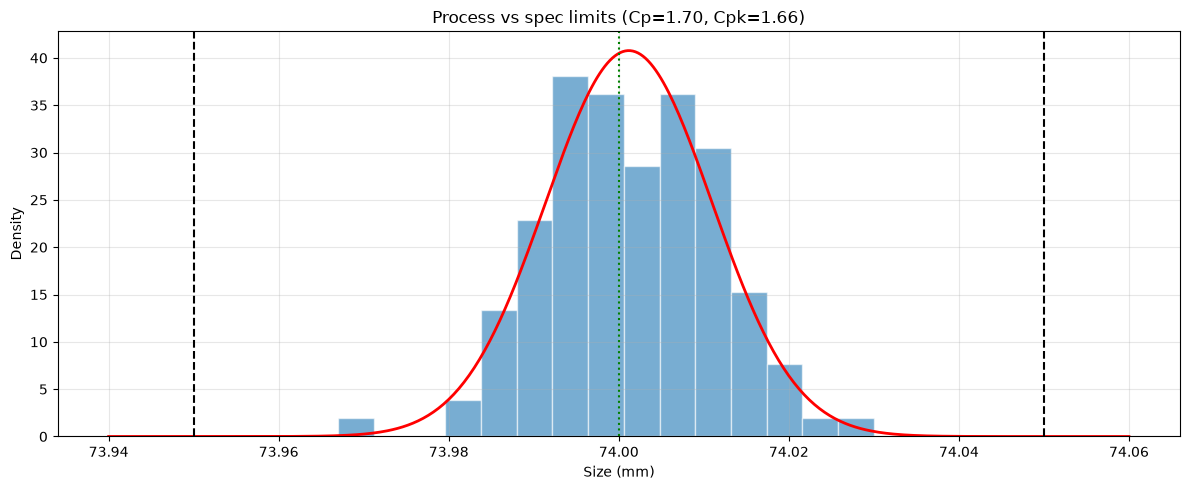

In [28]:
target, tol = 74.000, 0.050      # ← 実際の規格に合わせて変更
LSL, USL = target - tol, target + tol

sigma = rbar / d2                 # 群内σ
mean = df["size"].mean()

Cp  = (USL - LSL) / (6 * sigma)
Cpu = (USL - mean) / (3 * sigma)
Cpl = (mean - LSL) / (3 * sigma)
Cpk = min(Cpu, Cpl)

sig_t = df["size"].std()
Pp  = (USL - LSL) / (6 * sig_t)
Ppk = min((USL - mean), (mean - LSL)) / (3 * sig_t)

ppm = (stats.norm.cdf(LSL, mean, sigma) + stats.norm.sf(USL, mean, sigma)) * 1e6

res = pd.DataFrame({"value": [LSL, USL, mean, sigma, Cp, Cpk, Pp, Ppk, ppm]},
                   index=["LSL", "USL", "mean", "sigma(within)", "Cp", "Cpk", "Pp", "Ppk", "expected out-of-spec (ppm)"])
display(res.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(df["size"], bins=15, density=True, alpha=0.6, edgecolor="white")
xs = np.linspace(LSL - 0.01, USL + 0.01, 400)
ax.plot(xs, stats.norm.pdf(xs, mean, sigma), "r-", lw=2)
ax.axvline(LSL, color="k", ls="--"); ax.axvline(USL, color="k", ls="--")
ax.axvline(target, color="g", ls=":")
ax.set_title("Process vs spec limits (Cp=%.2f, Cpk=%.2f)" % (Cp, Cpk))
ax.set_xlabel("Size (mm)"); ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

## 9. まとめと考察

### 分かったこと
| 項目 | 結果 |
|---|---|
| 全体の平均・標準偏差 | 平均 74.0012 mm、標準偏差 0.0101 mm（最小 73.967 〜 最大 74.030） |
| 分布 | 歪度 −0.10、尖度 0.38、Shapiro-Wilk p=0.786 → **正規分布とみなせる** |
| X̄管理図 | 中心線 74.0012、限界 73.9880〜74.0143。**25サンプルすべて限界内** |
| R管理図 | R̄=0.0228、上限 0.0481。**すべて限界内**（最大は 14番の 0.039） |
| 異常パターン | 連続8点の偏り・6点連続の増減ともになし（最大は3点・4点） |
| サンプル間の差 | 分散分析 p=0.245 → 有意な差なし／平均の時系列トレンドも傾き −0.00005 mm/サンプル (p=0.75) でほぼ水平 |
| 工程能力（仮規格 74.000±0.050） | Cp=1.70、Cpk=1.66、規格外の期待値は約 0.4 ppm |

### ランキングから見えたこと
- **平均が最も高い**のは 1番 (74.0102)、次いで 20番・3番。**最も低い**のは 14番 (73.9902)、次いで 11番・6番。
- **ばらつきが最大**なのは 14番（範囲 0.039）と 1番（0.038）。両者は**平均の高低でも両端**にあり、全体の最小値 (73.967) は 14番、最大値 (74.030) は 1番に含まれます。
- **最も安定**していたのは 11番（範囲 0.008）、次いで 12番・7番。ただし 11番は平均が低め (73.9942) です。

### 考察
1. **工程は統計的に安定（管理状態）** です。管理限界外の点も、並びのクセ（偏り・トレンド）も見つからず、ばらつきは「偶然原因」によるものと考えられます。
2. 14番と1番は目立ちますが、**どちらも管理限界の内側**です。14番の平均 73.9902 は下限 73.9880 にかなり近く、1番の 74.0102 も上限 74.0143 に近いため、「異常ではないが、今後も要注意」という位置づけが妥当です。ランキングの順位差は、n=5 の小サンプルでは偶然でも生じる範囲だと考えられる
3. 平均と目標値 (74.000) の差は +0.0012 mm と小さく、Cp (1.70) と Cpk (1.66) がほぼ同じなので、**中心は規格の真ん中にほぼ合っています**。一般に Cpk 1.33 以上で十分、1.67 前後なら余裕のある工程とされます。
4. 全体σ (0.01007) と群内σ (0.00979) がほぼ等しく、サンプル間の変動が小さいことから、**日ごと・ロットごとの変動より、各サンプル内の一定のばらつきが主**だと言える。さらに改善するなら群内ばらつき自体を下げる必要がある。

### 注意点・今後の課題
- **規格値は仮定**です（74.000±0.050 mm）。実際の規格に合わせて第8章の `target`, `tol` を変えると Cp/Cpk が再計算されます。
- データは25サンプル(125個)と少なく、サンプルの取り方（時間順かどうか）も不明です。測定順に並んでいる前提でトレンド評価をしています。
- 管理限界は「このデータ自体」から計算しているため、今後の新しいデータを同じ限界線で監視（Phase II）すると、変化の検出に使えます。
- 次のステップ案: 14番・1番の測定時の条件（機械・工具・材料ロットなど）を確認、新しいデータでの継続監視、規格が分かれば不良率の再評価。